<a href="https://colab.research.google.com/github/ayeshaazahidd0-stack/Digital-Image-Processing/blob/main/Lab_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving e4e83b3c616e289eda796089a87776_big_gallery.jpeg to e4e83b3c616e289eda796089a87776_big_gallery (1).jpeg


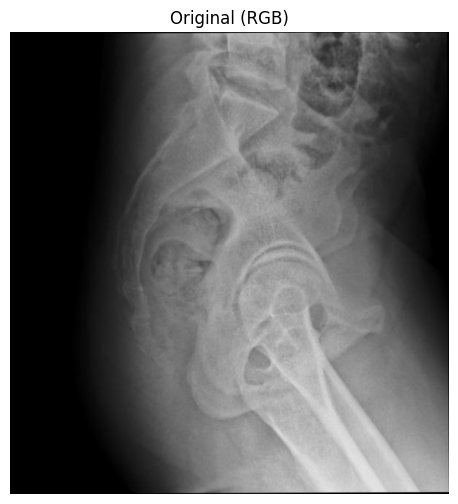

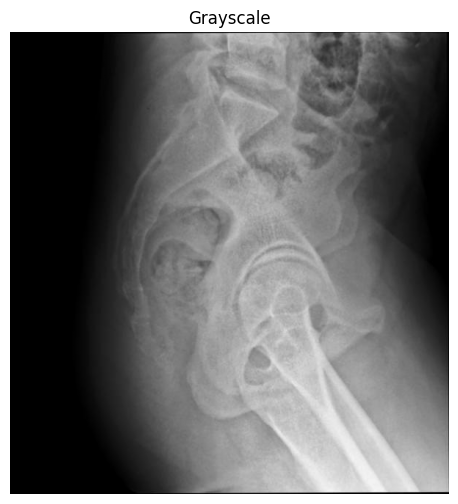

In [5]:
#UpLoad ONE image
from google.colab import files
up = files.upload()
IMG = list(up.keys())[0]
# Basics
import cv2, numpy as np, matplotlib.pyplot as plt
# Read & prep
bgr = cv2.imread(IMG, cv2.IMREAD_COLOR)
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
def show(im, title="", size=5, cmap=None):
    plt.figure(figsize=(size,size))
    if im.ndim == 2:
        plt.imshow(im, cmap=cmap or "gray")
    else:
        plt.imshow(im)
    plt.title(title)
    plt.axis("off")
    plt.show()
show(rgb, "Original (RGB)", 6)
show(gray, "Grayscale", 6, "gray")

**Task 1- Laplacian (simple edge detector)**

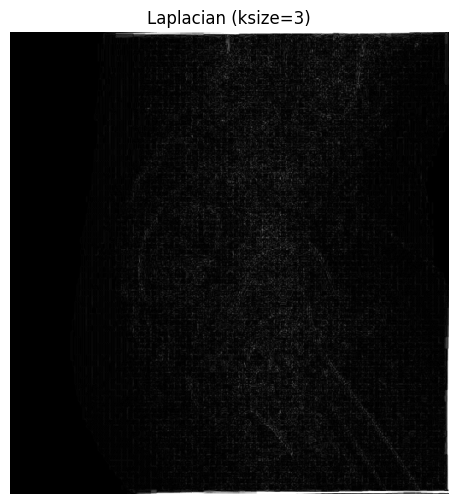

In [6]:
#ksize must be odd kappa > 1 (use 3 for beginners)
lap = cv2. Laplacian (gray, ddepth=cv2.CV_64F, ksize=3)
lap_abs = cv2.convertScaleAbs (lap) # for display
show(lap_abs, "Laplacian (ksize=3)", 6, "gray")

**Task 2- Sobel X and Y, then edge magnitude**

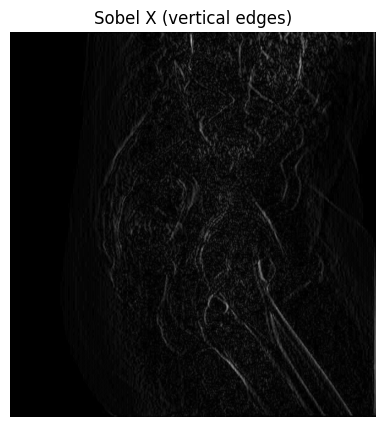

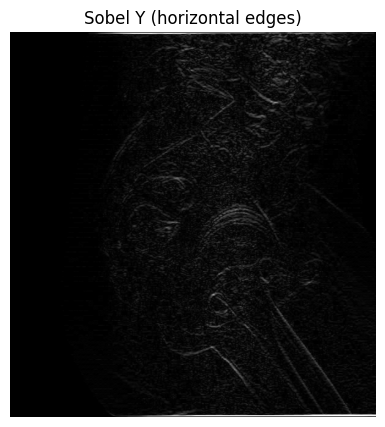

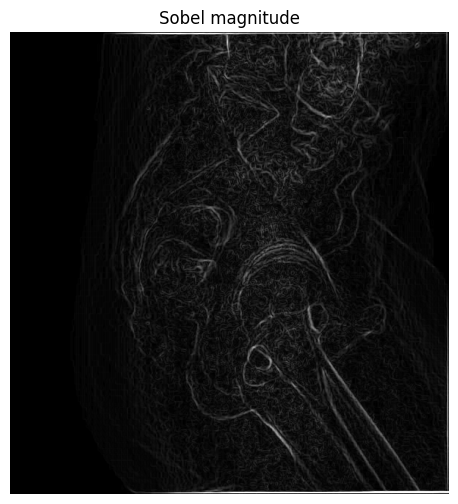

In [7]:
sobel_x = cv2.Sobel (gray, cv2.CV_64F, 1, 0, ksize=3)
# d/dx
sobel_y = cv2.Sobel (gray, cv2.CV_64F, 0, 1, ksize=3)
#d/dy
abs_x = cv2.convertScaleAbs (sobel_x)
abs_y= cv2.convertScaleAbs (sobel_y)
mag = cv2.magnitude (sobel_x, sobel_y)
#sqrt(sx^2 + sy^2)
mag8 = cv2.convertScaleAbs (mag)
show(abs_x, "Sobel X (vertical edges)", 5, "gray")
show(abs_y, "Sobel Y (horizontal edges)", 5, "gray")
show(mag8, "Sobel magnitude", 6, "gray")

**Task 3 - Prewitt X/Y and magnitude (manual kernels)**

In [8]:
# Prewitt 3x3 kernels
kx = np.array([[-1,0,1],
[-1,0,1],
[-1,0,1]], dtype=np.float32)
ky= np.array([[-1,-1,-1],
[ 0, 0, 0],
[1, 1, 1]], dtype=np.float32)
prew_x = cv2.filter2D (gray, cv2.CV_32F, kx)
prew_y = cv2.filter2D(gray, cv2.CV_32F, ky)
prew_mag = cv2.magnitude (prew_x, prew_y)
show(cv2.convertScaleAbs (prew_x), "Prewitt X", 5, "gray")
show(cv2.convertScaleAbs (prew_y), "Prewitt Y", 5, "gray")

SyntaxError: closing parenthesis ')' does not match opening parenthesis '[' on line 5 (1810396482.py, line 7)

**Task 4: Sobel vs Prewitt (quick visual compare)**

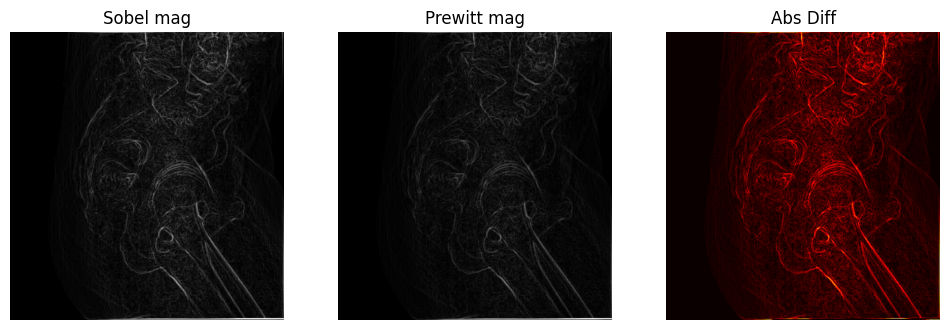

In [11]:
# Define Prewitt kernels and calculate prew_mag locally to avoid NameError
kx = np.array([[-1,0,1], [-1,0,1], [-1,0,1]], dtype=np.float32)
ky = np.array([[-1,-1,-1], [ 0, 0, 0], [1, 1, 1]], dtype=np.float32)
prew_x = cv2.filter2D(gray, cv2.CV_32F, kx)
prew_y = cv2.filter2D(gray, cv2.CV_32F, ky)
prew_mag = cv2.magnitude(prew_x, prew_y)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1); plt.imshow(mag8, cmap="gray"); plt.title("Sobel mag");
plt.axis("off")
plt.subplot(1,3,2); plt.imshow(cv2.convertScaleAbs(prew_mag), cmap="gray"); plt.title("Prewitt mag"); plt.axis("off")
plt.subplot(1,3,3); plt.imshow(cv2.absdiff(mag8, cv2.convertScaleAbs(prew_mag)), cmap="hot"); plt.title("Abs Diff"); plt.axis("off")
plt.show()

**Task 5 : Canny edge Detection**

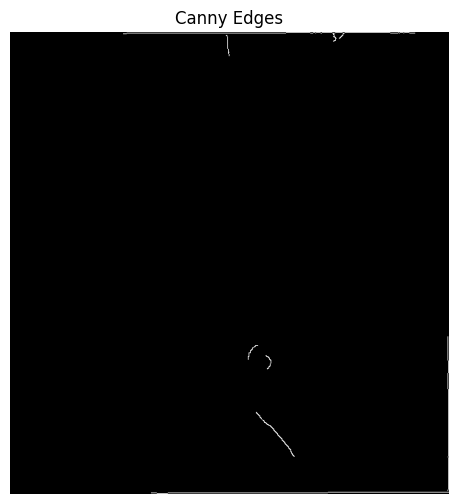

In [13]:
# Canny edge detection
edges = cv2.Canny (gray, threshold1=100, threshold2=200)
show(edges, "Canny Edges", 6, "gray")